# 🔄 Reinforcement Learning!

📊 **High-level goal:**
Train an agent (the “learner”) to interact with the given environment and learn from it, so it can maximize its cumulative rewards over time.
*   **Environment:**
     *   The environment **is already created** and set up for you with the help of the
"gymnasium" library.
     *   The agent interacts with a simulated environment, which has states, accepts actions, and returns rewards. The environment resets at the beginning of each episode, and the agent takes actions within it, receiving feedback in the form of rewards.
*   **Q-table:**
     *   This table stores information about the "quality" of actions in different states.
     *   The goal of the agent is to update the Q-table over time to better estimate the value of taking different actions in various states.
     *   You will initialize and learn a Q-table in this project.

## 🗂️ Project structure

1. Following the task description, you'll find a set of formal requirements that your solution must meet.
2. After completing each task, you must answer a series of questions, marked with ❓, to demonstrate your understanding of the techniques used.

## 📝 Submission guidelines

- For each problem, provide your code solution and model results inside this notebook.
- Answer the follow-up questions in markdown format within this notebook. A few sentences are enough; there is no length requirement.
- Ensure your explanations are clear, concise, and demonstrate a deep understanding of the techniques employed.
- Submit this notebook to Canvas. Deliver the notebook with its outputs saved; ideally, *restart* the kernel and then *run all*.

Good luck!

---

### 📮 Imports:

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import os
from utils import *

# note: make sure to install necessary libraries like imageio, gymnasium etc.
# !pip install gymnasium

In [2]:
import gymnasium as gym
from gymnasium.spaces import Discrete, MultiDiscrete

### Environment class with necessary functions - provided for you:

In [3]:
class TrondheimEnv(gym.Env):
    metadata = {'render.modes': ['human']}

    def __init__(self, conf: dict):
        """
        Every environment should be derived from gym.Env and at least contain
        variables observation_space and action_space specifying the type of possible
        observations and actions using spaces.Box or spaces.Discrete.

        Example:
        >>> EnvTest = TrondheimEnv()
        >>> EnvTest.observation_space=spaces.Box(low=-1, high=1, shape=(3,4))
        >>> EnvTest.action_space=spaces.Discrete(2)
        """

        self.verbose = True  # Flag to control printouts

        # action definition:
        NUM_ACTIONS = 4
        self.action_space = Discrete(NUM_ACTIONS)

        self.env_image_path = conf['env_image_path']

        self.pallete = np.array([
                            [0, 0, 255],    # Blue:0:Water
                            [255, 255, 0],  # Yellow:1:Start
                            [0, 255, 0],    # Green:2:Land
                            [255, 0, 0],    # Red:3:BusLane
                            [128, 0, 128],  # Purple:4:BusStop
                            [0, 0, 0]],      # Black:5:Final Location
                           dtype=np.uint8)
                            # [128, 128, 0]], # Olive:5:Final Location

        self.neighbours = np.array([[-1,0],[0,-1],[1,0],[0,1]]) # up, left, down, right
        self.not_allowed_area = [0] # water
        self.start_class = 1 # start
        self.normal_land_class = 2 # land
        self.busstop_class = 4 # bus stop
        self.final_location_class = 5 # final location (2)

        # does the agent die when entering not_allowed_area
        self.dead_allowed = conf['dead_allowed']
        # should we start at different place each time
        self.start_random = conf['start_random']

        # read RGB image into a 3D numpy array
        img_3d = read_png_file(self.env_image_path, printDebug = False)

        # convert RGB image into 2D semantic class representation
        img_2d = make_2d(map_3d=img_3d, palette_array=self.pallete)

        # the current state of the environment
        self.observation = img_2d # initial observation - 2D semantic class
        # copy of the environment's initial state before any actions have been taken
        self.initial_observation = img_2d.copy()

        max_observation_value = np.max(img_2d)
        # observation space is a gym object (MultiDiscrete), like numpy array. It can be sampled
        observation_space = np.full_like(img_2d, fill_value=max_observation_value)
        self.observation_space = MultiDiscrete(observation_space)

        self.reward = 0
        self.terminated = False
        
    def step(self, action: int) -> tuple[np.ndarray, float, bool, dict]:
        """
        This method is the primary interface between environment and agent.

        Parameters:
            action: the index of the respective action

        Returns:
            output: information provided by the environment about its current state:
                    (observation, reward, terminated, info)

                    self.observation: The updated state of the environment (2D)
                    reward: Reward agent received for the action in this step 
                    terminated: indicate if the episode has ended
                    info: Additional information (not used, always None)

        """
        obs = self.observation # 2D array of semantic class image representation
        terminated = False
        info = None
        
        # just start and see where it goes
        start_idx = np.argwhere(obs == self.start_class)[0]
        # action is: 0:up, 1:left, 2:down, 3:right
        next_idx = start_idx + self.neighbours[action]
        reward = self.reward
        
        if self.verbose:
          print('Next step towards: ')

        if not is_valid_idx(image_2D=obs, selected_idx=next_idx):
            next_idx = start_idx
            if self.verbose:
                print('Hey there, you cannot escape outside of the environment')

        # now decide what happens next
        if obs[tuple(next_idx)] == self.normal_land_class:
            if self.verbose:
                print('Green Land class area')

        # check if it is a non allowed area
        if obs[tuple(next_idx)] in self.not_allowed_area:
            if self.verbose:
                print('The move is not allowed')
            if self.dead_allowed:
                # penalize the agent if allowed to die. Terminate
                reward = -1
                terminated = True
            else:
                # if NOT allowed to die, reset the next position to current one - prevent the move
                next_idx = start_idx

        # if the player is at a bus stop
        elif obs[tuple(next_idx)] == self.busstop_class:
            if self.verbose:
                print('A bus stop')

            # get the bus stop that is not the next step
            bus_stop_indices = np.argwhere(obs == self.busstop_class)
            # flip the next state to the other side of the stop
            if np.array_equal(next_idx, bus_stop_indices[0]):
                # teleport the agent from bus stop 0 to bus stop 1
                next_idx = bus_stop_indices[1]
            else:
                # teleport the agent from bus stop 1 to bus stop 0
                next_idx = bus_stop_indices[0]

        # and the Final Location
        elif obs[tuple(next_idx)] == self.final_location_class:
            if self.verbose:
                print('Final Location - well done!')
                print('You have discovered the Final Location of AI center in Trondheim')
            reward = 10
            terminated = True

        # now we need to change the observation space
        # i.e. update the environment’s state to reflect the agent's movement

        # if agent’s current position was initial start position
        if self.initial_observation[tuple(start_idx)] == self.start_class:
            # if true, update observation - mark the start position as neutral area
            self.observation[tuple(start_idx)] = self.normal_land_class
        else:
            # if current position not the initial start one
            # restores position in self.observation to its original value from self.initial_observation
            # re-color the observation as where you were if not start position
            self.observation[tuple(start_idx)] = self.initial_observation[tuple(start_idx)]

        # sets the new position of the agent as the next start position
        self.observation[tuple(next_idx)] = self.start_class

        self.terminated = self.terminated or terminated

        return self.observation, reward, terminated, info


    def reset(self) -> np.ndarray:
        """
        This method resets the environment to its initial values.
        """

        img_3d = read_png_file(self.env_image_path, printDebug = False)
        img_2d = make_2d(map_3d=img_3d, palette_array=self.pallete)

        if self.start_random:
          # we need to move the start to another place
          img_2d = swap_values(arr=img_2d, value1=1, value2=2)

        self.observation = img_2d
        self.initial_observation = img_2d.copy()

        max_observation_value = np.max(img_2d)
        observation_space = np.full_like(img_2d, fill_value=max_observation_value)
        self.observation_space = MultiDiscrete(observation_space)

        self.reward = 0
        self.terminated = False

        return self.observation
        
    def get_state_id(self):
        """
        This method converts the observation to a unique id that we will use to index the Q table.
        """
        rows, cols = self.observation.shape
        grid_size = rows * cols

        agent_pos = np.argwhere( self.observation == self.start_class)[0]
        agent_row, agent_col = agent_pos[0], agent_pos[1]

        grid_index = (agent_row * cols) + agent_col

        return grid_index

    def render(self, mode: str = "", close: bool = False) -> np.ndarray:
        """
        This method provides the option to render the environment's behavior to a
        window which should be readable to the human eye if mode is set to 'human'.
        """
        render_ready_arr = make_3d(map_2d=self.observation, palette_array=self.pallete)
        if mode == "human":
            plt.imshow(render_ready_arr)
            plt.show()
            plt.close()
        return render_ready_arr

    def close(self):
        img_3d = read_png_file(self.env_image_path)
        img_2d = make_2d(map_3d=img_3d, palette_array=self.pallete)
        self.observation = img_2d
        self.initial_observation = img_2d.copy()


### Configuring and loading the environment:

#### 🔎📉  Let's first visualize our simple toy environment

In [4]:
# This is how you create a configuration for the environment
env_config = {
    'env_image_path':'image_simple.png',
    'dead_allowed':False,
    'start_random':False,
}


if not os.path.exists(env_config['env_image_path']):
  # make sure you have the folder and the image
  print(f"Error: The image path {env_config['env_image_path']} does not exist.")
else:
  # if everything fine, we create the environment
  env = TrondheimEnv(conf=env_config)
  print(f"Environment successfully created")

Environment successfully created


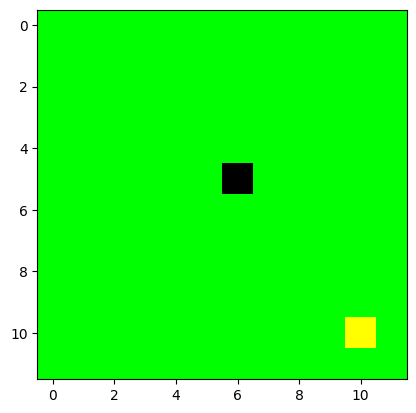

In [5]:
# visualize the environment. Yellow is where we are, Black is where we want to go
env.reset()
_ = env.render("human")

Let's see how actions work:

In [6]:
action_dict = {
    'up':0,
    'left':1,
    'down':2,
    'right':3,
}

Next step towards: 
Green Land class area
Reward for action left is: 0


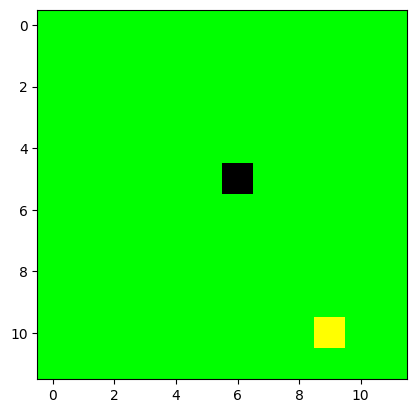

Observation space looks like this:
[[2 2 2 2 2 2 2 2 2 2 2 2]
 [2 2 2 2 2 2 2 2 2 2 2 2]
 [2 2 2 2 2 2 2 2 2 2 2 2]
 [2 2 2 2 2 2 2 2 2 2 2 2]
 [2 2 2 2 2 2 2 2 2 2 2 2]
 [2 2 2 2 2 2 5 2 2 2 2 2]
 [2 2 2 2 2 2 2 2 2 2 2 2]
 [2 2 2 2 2 2 2 2 2 2 2 2]
 [2 2 2 2 2 2 2 2 2 2 2 2]
 [2 2 2 2 2 2 2 2 2 2 2 2]
 [2 2 2 2 2 2 2 2 2 1 2 2]
 [2 2 2 2 2 2 2 2 2 2 2 2]]


In [7]:
# select your action here
# you are encouraged to play further with this
my_action = 'left'

# now take a step through the environment by taking this action
obs, rew, term, info = env.step(action_dict[my_action])
print(f"Reward for action {my_action} is: {rew}")
env.render("human")

print(f"Observation space looks like this:\n{obs}")

## 🐮 Problem 1: Q-learning in a simple toy environment
### ❗️ The problem
In the first problem, you will train an agent to navigate from a start position (yellow) to a goal position (black) in a simple grid environment using Q-learning.

### 📋 Formal requirements
1. **Implementation**:
   - Initialize the Q-table
   - Write the necessary helper functions for Q-learning (exploration rate, learning rate and action selection)
   - Choose and tune the hyperparameters
   - Train the agent using Q-learning
   - Run one episode with the trained agent and verify that it reaches the goal
   - Visualize the learned Q-values as heatmaps
2. **Discussion**:
   - Why do we need an exploration rate?
   - Why do we update the learning rate?
   - Explain all terms of the Q-learning update rule.
   - What do the heatmaps show?
   - Why does the Q-table have 144 states?
   - What happens with γ = 0 or γ = 1?
   - Every step gives reward 0. How does the agent still learn the shortest path?
   - What happens if the exploration rate is 0 from the start?
   - Why do we set the exploration rate to 0 when we show the trained agent?

### 🐣 Let's learn how to do this in a simple environment

In [8]:
env_config = {
    'env_image_path':'image_simple.png',
    'dead_allowed':False,
    'start_random':False,
}

if not os.path.exists(env_config['env_image_path']):
  print(f"Error: The image path {env_config['env_image_path']} does not exist.")
else:
  env = TrondheimEnv(conf=env_config)
  print(f"Environment successfully created")

Environment successfully created


### Step 1: Initialize Q table

In [9]:
# Task 1: Initialize Q table
"""
TODO: given the environment, initialize the Q table
"""

# Tip: pay attention to the dimensions of Q table
# Tip: how many states does the table have, how many actions

# ====================================
# YOUR CODE GOES HERE
# ====================================
# one state per grid cell (the agent's position), one column per action
num_states = int(np.prod(env.observation_space.shape))  # 12 * 12 = 144
num_actions = env.action_space.n                         # up, left, down, right
q_table = np.zeros((num_states, num_actions))

In [10]:
# take a look at the initial Q table
print(f"Q table has this shape: {q_table.shape}\n")

# you may want to print Q table, or parts of it, to get the vibe
# print(q_table[:10])
print(f"\n")
# print(q_table[135:])

Q table has this shape: (144, 4)





### ❓ Why does the Q-table have 144 states?
The state is only the **position of the agent** (`get_state_id()` returns `row * ncols + col`). Everything else in the map is static, so the position is all the agent needs to know. The grid is 12 × 12 = **144 cells**, so there are 144 states, and each state has one Q-value per action (up, left, down, right). That gives a 144 × 4 table. The goal cell is terminal, so its row is never updated.

### Step 2: Write necessary helper functions for Q-learning

In [11]:
def update_explore_rate(episode: int, epsilon_min: float, max_episodes: int, epsilon_max: float = 1.0):
    """controls the balance between exploration and exploitation"""
    # ====================================
    # YOUR CODE GOES HERE: return updated explore_rate
    # ====================================
    # exponential decay from epsilon_max towards epsilon_min, ~epsilon_min after 80-100% of the episodes
    return epsilon_min + (epsilon_max - epsilon_min) * np.exp(-5 * episode / max_episodes)

def update_learning_rate(episode: int, min_learning_rate: float, max_episodes: int):
    """controls how aggressively the agent updates its knowledge"""
    # ====================================
    # YOUR CODE GOES HERE: return updated learning_rate
    # ====================================
    # same schedule: start at 1.0 (overwrite the estimate) and decay towards min_learning_rate
    return min_learning_rate + (1.0 - min_learning_rate) * np.exp(-5 * episode / max_episodes)

def update_action(env, state: int, explore_rate: float, q_table: np.ndarray) -> int:
    """uses the exploration rate to decide whether to take a random action (explore)
    or to act according to the learned Q-values (exploit)"""
    # ====================================
    # YOUR CODE GOES HERE: return an action
    # ====================================
    if np.random.random() < explore_rate:
        return int(np.random.randint(env.action_space.n))  # explore
    return int(np.argmax(q_table[state]))                   # exploit

### ❓ Why do we need an exploration rate?
At the start every Q-value is 0, so the "best" action is arbitrary (`np.argmax` always returns action 0 = up). An agent that always picks the best action would only repeat what it already believes. It would never find the goal or better paths it has not tried. The exploration rate ε is the probability of taking a random action instead (ε-greedy). It starts at 1 (we know nothing, so we explore everything) and decays towards 0.01. Then the agent mostly exploits what it has learned, but still sometimes checks alternatives. The experiment below shows that with ε = 0 the agent never reaches the goal.

### ❓ Why do we update the learning rate?
The learning rate α decides how much a new sample overwrites the old estimate. Early in training the Q-values are far from correct and the targets change quickly, so a large α (1.0) learns fast. Later we want the values to **settle**. A smaller α averages over many updates, so a single random exploration step or a random start does not throw away what was learned, and the Q-values converge. In theory, convergence requires Σα = ∞ and Σα² < ∞. Our toy environment is deterministic, so a large α would also work here. In noisy settings (random starts, stochastic transitions), a decaying α is needed to get stable values.

### Step 3: Play with Hyperparameters

In [12]:
# ====================================
# YOUR CODE GOES HERE: replace None with your values
# ====================================
GAMMA = 0.95                 # discount factor
NUM_EPISODES = 500
MAX_STEPS_PER_EPISODE = 200
EPSILON = 1.0                # start exploration rate (fully random)
EPSILON_MIN = 0.01
MIN_LEARNING_RATE = 0.1

### 🐤 Now use Q learning to learn the Q table
### Step 4: Train the agent using Q-learning

The Q-value update equation, derived from Bellman equation is as follows:


$$
Q(s, a) \gets Q(s, a) + \alpha \cdot \Big[ R(s, a) + \gamma \cdot \max_{a'} Q(s', a') - Q(s, a) \Big]
$$

### ❓ Explain all terms of the Q-learning update rule.
- **Q(s, a)**: the current estimate of the expected discounted return when taking action a in state s and then acting optimally.
- **α**: the learning rate (0–1). It sets how far we move the estimate towards the new target.
- **R(s, a)**: the immediate reward for taking a in s: 0 per step, +10 at the goal, −1 in the water if `dead_allowed`.
- **γ**: the discount factor (0–1). It sets how much future rewards are worth compared to immediate ones.
- **s'**: the next state, where the agent ends up after taking a.
- **a'**: the possible actions in the next state s'.
- **max Q(s', a')**: the value of the best action in the next state. It estimates the future return if we act optimally from s'. Using the max instead of the action actually taken makes Q-learning off-policy.

The term in the brackets is the **TD error**: the target R + γ·max Q(s', a') minus the current estimate. If s' is terminal, there is no future, and the target is only R.

In [13]:
# Suggestion: you can wrap the code to learn Q-table in a function,
# which you can also reuse in Problem 2

# result of the training is:
#   updated Q table (q_table)
#   total_reward
#   you are free to add others, if you wish

env.verbose = False # disable printouts while training

# ====================================
# YOUR CODE GOES HERE
# ====================================

def train_q_learning(env, q_table, num_episodes, max_steps, gamma, epsilon_min, min_learning_rate,
                     epsilon=1.0, seed=0):
    """Tabular Q-learning. Returns the Q table, the total reward summed over all episodes,
    the number of steps and the reward in each episode and the final exploration and learning rates."""
    np.random.seed(seed)  # exploration (and random starts) become reproducible
    env.verbose = False
    total_reward = 0
    steps_per_episode = []
    rewards_per_episode = []

    # iterate over number of episodes
    for episode in range(num_episodes):
        env.reset()  # remember to reset the state!
        state = env.get_state_id()
        # update the exploration and learning rate
        explore_rate = update_explore_rate(episode, epsilon_min, num_episodes, epsilon)
        learning_rate = update_learning_rate(episode, min_learning_rate, num_episodes)

        # iterate over number of steps in each episode
        for step in range(max_steps):
            # get action and step through the environment
            action = update_action(env, state, explore_rate, q_table)
            _, reward, terminated, _ = env.step(action)
            next_state = env.get_state_id()

            # update the q-table (no future reward after a terminal state)
            target = reward if terminated else reward + gamma * np.max(q_table[next_state])
            q_table[state, action] += learning_rate * (target - q_table[state, action])

            total_reward += reward
            state = next_state
            # check if we are done
            if terminated:
                break
        steps_per_episode.append(step + 1)
        rewards_per_episode.append(reward)  # the last reward: 10 at the goal, -1 in the water, else 0

    return q_table, total_reward, np.array(steps_per_episode), np.array(rewards_per_episode), explore_rate, learning_rate


q_table, total_reward, steps_per_episode, rewards_per_episode, explore_rate, learning_rate = train_q_learning(
    env, q_table, NUM_EPISODES, MAX_STEPS_PER_EPISODE, GAMMA, EPSILON_MIN, MIN_LEARNING_RATE, epsilon=EPSILON)

print(f"Reached the goal in {np.sum(rewards_per_episode == 10)}/{NUM_EPISODES} episodes")
print(f"Steps in the first 5 episodes: {steps_per_episode[:5]}, in the last 5: {steps_per_episode[-5:]}")
print(f"Final learning rate: {learning_rate:.4f}")

Reached the goal in 492/500 episodes
Steps in the first 5 episodes: [ 75 159 200 120 200], in the last 5: [9 9 9 9 9]
Final learning rate: 0.1061


In [14]:
print(f"Total reward after training: {total_reward}, total Explore rate after training: {explore_rate:.4f}")

Total reward after training: 4920, total Explore rate after training: 0.0167


### 🐥 Let's see this in action

In [15]:
# now we show one episode
# yellow spot should be able to find black spot here
# If you want to see frame by frame, remember to pass "human" as argument in env.render()!

env.verbose = False # set to True to enable messages
NUM_STEPS = 32

observation = env.reset()
state_id = env.get_state_id()
total_reward = 0

image_samples = []

img = env.render()
for _ in range(NUM_STEPS):
    action = update_action(env, state_id, 0, q_table) # explore rate 0: always pick the best action
    observation, reward, terminated, info = env.step(action)
    state_id = env.get_state_id()
    total_reward += reward
    img = env.render()
    image_samples.append(img)
    if terminated:
        break

print(f"Total_reward: ", total_reward)

Total_reward:  10


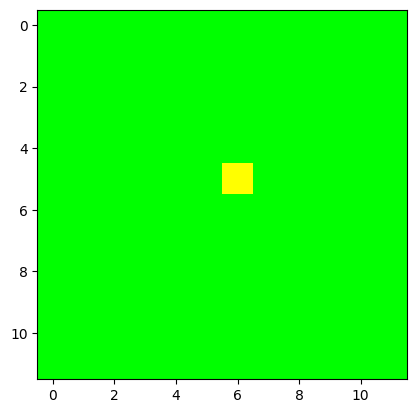

In [16]:
# let's make an animation of this, because it's fun
# nothing for you to do here - just run the code
# and open the animation.gif in output/

import os
import matplotlib.animation as animation

height = img.shape[0]
width = img.shape[1]

output_folder = 'output'
if not os.path.exists(output_folder):
    os.makedirs(output_folder)


fig = plt.figure()
imgs = []
for i in range(len(image_samples)):
    im = plt.imshow(image_samples[i].reshape(height, width, 3), animated=True)
    imgs.append([im])

animate = animation.ArtistAnimation(fig, imgs, interval=80, blit=True, repeat_delay=1000)
filename_gif = os.path.join(output_folder, 'animation.gif')
animate.save(filename_gif)
plt.show()

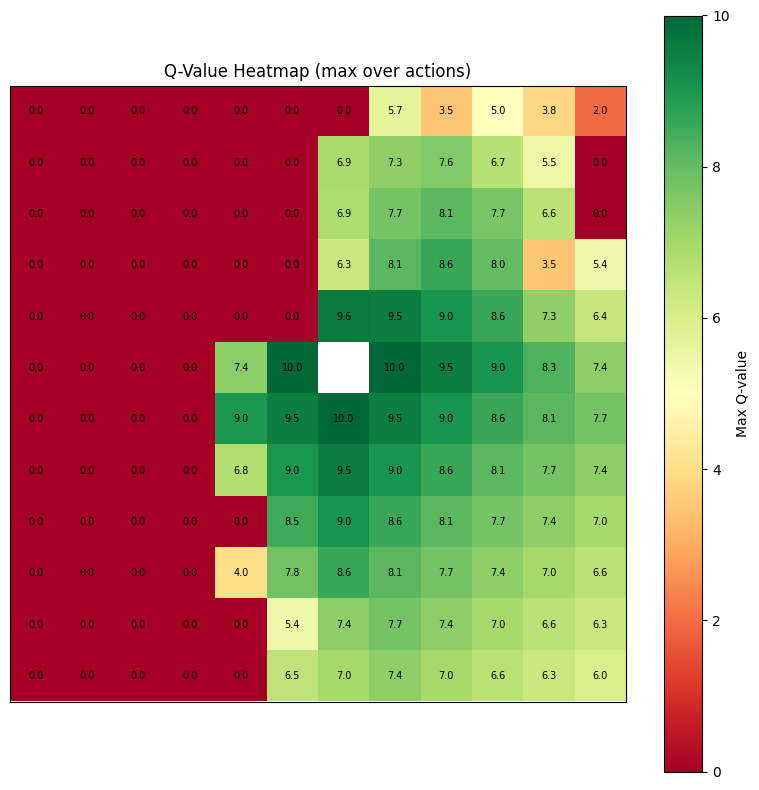

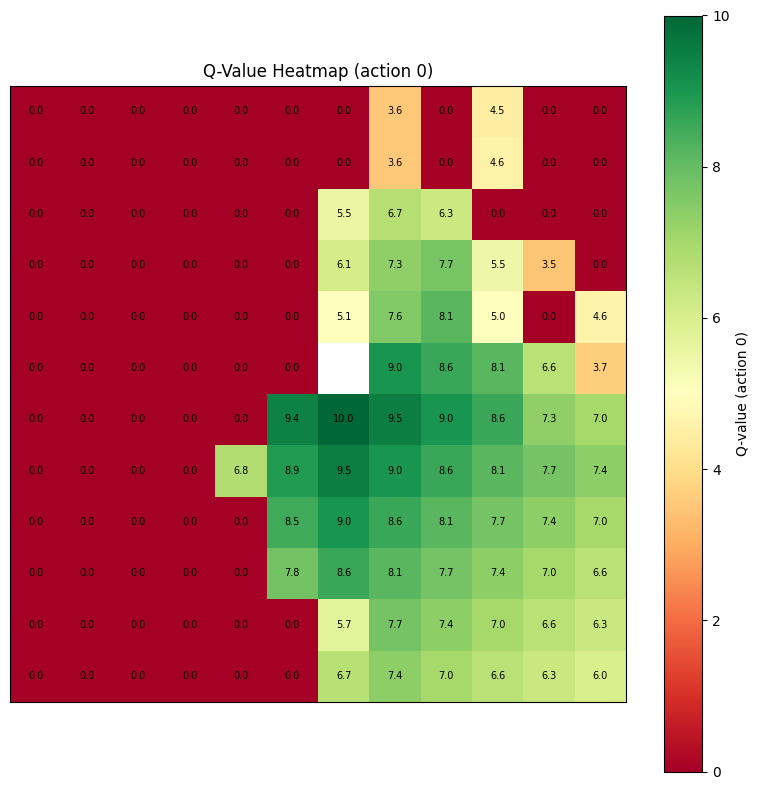

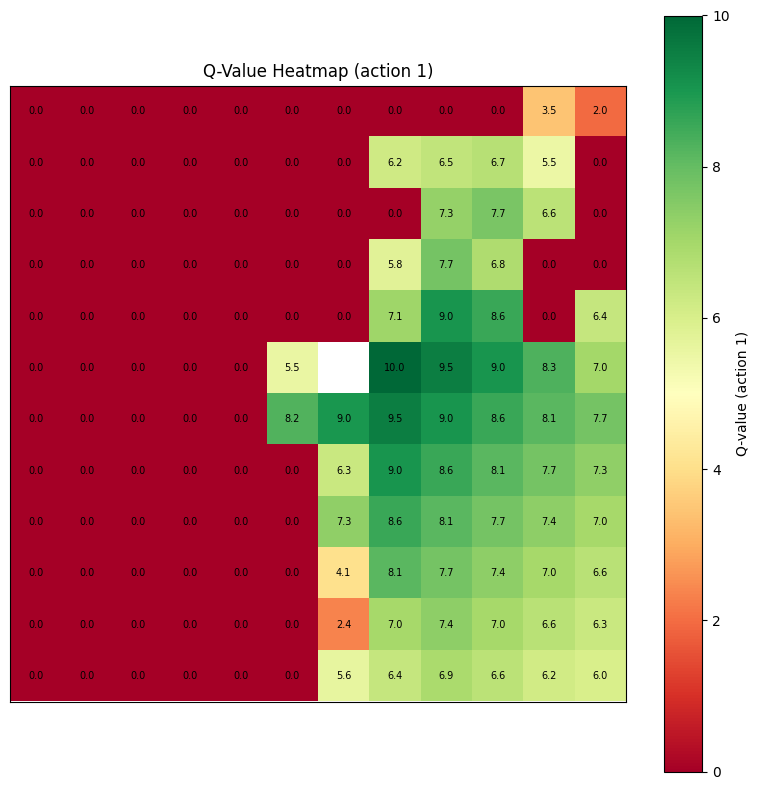

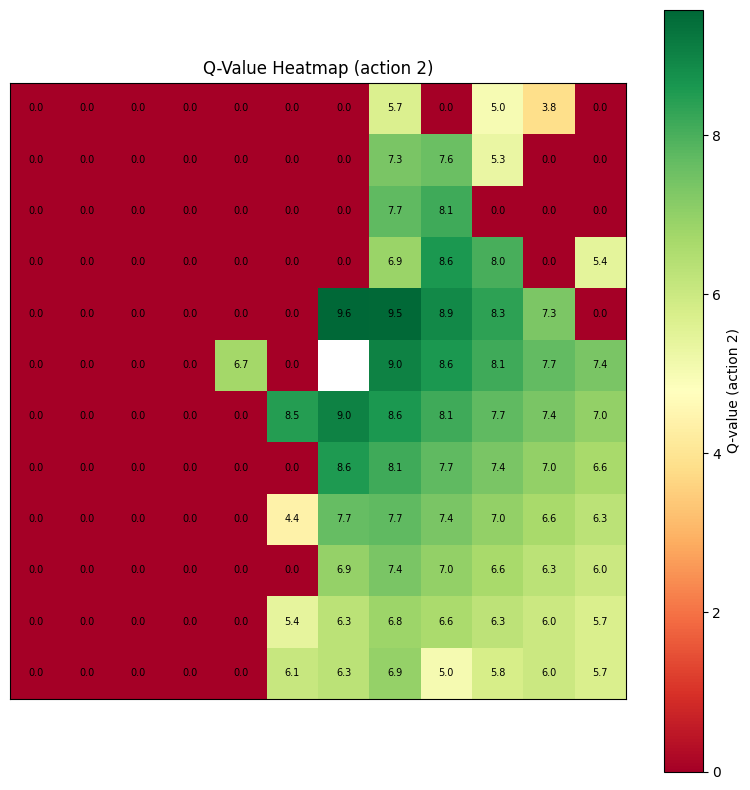

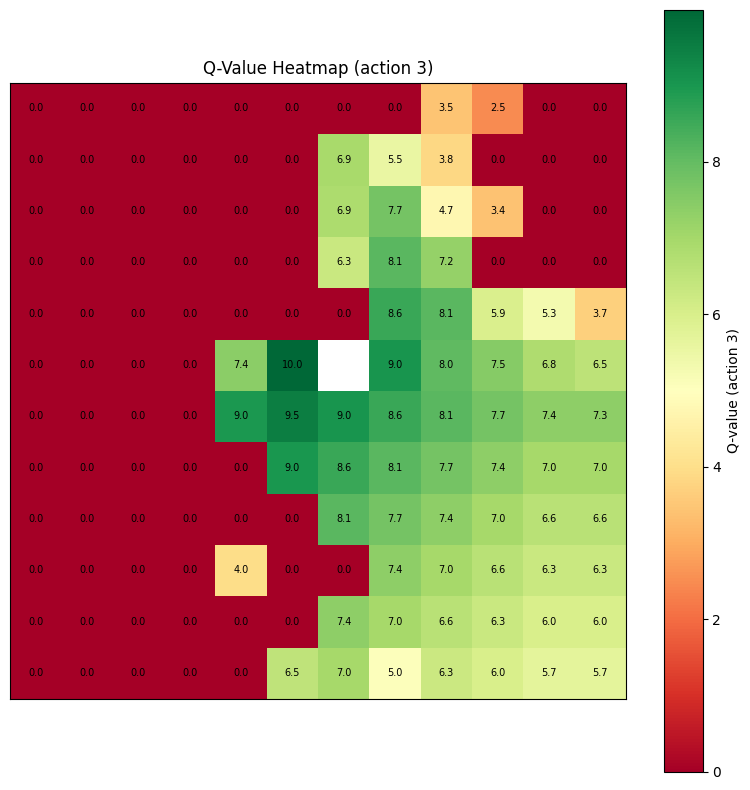

In [17]:
# Let's visualize the Q values now!
def show_q_heatmap(env, q_table, action: int = None):
    # ====================================
    # YOUR CODE GOES HERE
    # ====================================
    nrows, ncols = env.initial_observation.shape
    if action is None:
        q_grid = q_table.max(axis=1).reshape(nrows, ncols)
    else:
        q_grid = q_table[:, action].reshape(nrows, ncols).copy()
    # the agent can never stand on water, and the goal is terminal (never updated): leave them blank
    blank = np.isin(env.initial_observation, env.not_allowed_area + [env.final_location_class])
    q_grid = np.where(blank, np.nan, q_grid)
    annotate = ncols <= 16  # numbers are unreadable on large maps
    # ====================================
    fig, ax = plt.subplots(figsize=(8, 8))
    im = ax.imshow(q_grid, cmap='RdYlGn', interpolation='nearest')
    fig.colorbar(im, ax=ax, label='Max Q-value' if action is None else f'Q-value (action {action})')

    for r in range(nrows):
        for c in range(ncols):
            if annotate and not np.isnan(q_grid[r, c]):
                ax.text(c, r, f'{q_grid[r, c]:.1f}', ha='center', va='center',
                        fontsize=7, color='black')

    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_title("Q-Value Heatmap " + (f"(action {action})" if action is not None else "(max over actions)"))
    fig.tight_layout()
    plt.show()

show_q_heatmap(env, q_table)
show_q_heatmap(env, q_table, 0)
show_q_heatmap(env, q_table, 1)
show_q_heatmap(env, q_table, 2)
show_q_heatmap(env, q_table, 3)

In [18]:
print(q_table.shape)
print(f"Obs space dimensions :{env.observation_space.shape}")

(144, 4)
Obs space dimensions :(12, 12)


In [19]:
q_table.argmax(axis=1).reshape(env.observation_space.shape)

array([[0, 0, 0, 0, 0, 0, 0, 2, 3, 2, 2, 1],
       [0, 0, 0, 0, 0, 0, 3, 2, 2, 1, 1, 0],
       [0, 0, 0, 0, 0, 0, 3, 3, 2, 1, 1, 0],
       [0, 0, 0, 0, 0, 0, 3, 3, 2, 2, 0, 2],
       [0, 0, 0, 0, 0, 0, 2, 2, 1, 1, 2, 1],
       [0, 0, 0, 0, 3, 3, 0, 1, 1, 1, 1, 2],
       [0, 0, 0, 0, 3, 3, 0, 0, 1, 1, 1, 1],
       [0, 0, 0, 0, 0, 3, 0, 0, 0, 0, 1, 0],
       [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1],
       [0, 0, 0, 0, 3, 0, 0, 0, 0, 0, 0, 1],
       [0, 0, 0, 0, 0, 2, 3, 0, 1, 0, 0, 0],
       [0, 0, 0, 0, 0, 3, 3, 0, 0, 0, 0, 0]])

In [20]:
env.close()

image has more than 3 channels, only first 3 channels are used there are (12, 12, 4) channels


### 🧪 Experiments for the discussion questions
Retrain from scratch with γ = 0, γ = 1 and with the exploration rate fixed at 0, and run the greedy agent each time.

γ = 0.95 (baseline)  goal reached in 492/500 training episodes | greedy agent: reward 10, 9 steps | non-zero Q-values: 249


γ = 0                goal reached in  25/500 training episodes | greedy agent: reward 0, 100 steps | non-zero Q-values: 3


γ = 1                goal reached in 492/500 training episodes | greedy agent: reward 10, 9 steps | non-zero Q-values: 279


explore rate = 0     goal reached in   0/500 training episodes | greedy agent: reward 0, 100 steps | non-zero Q-values: 0


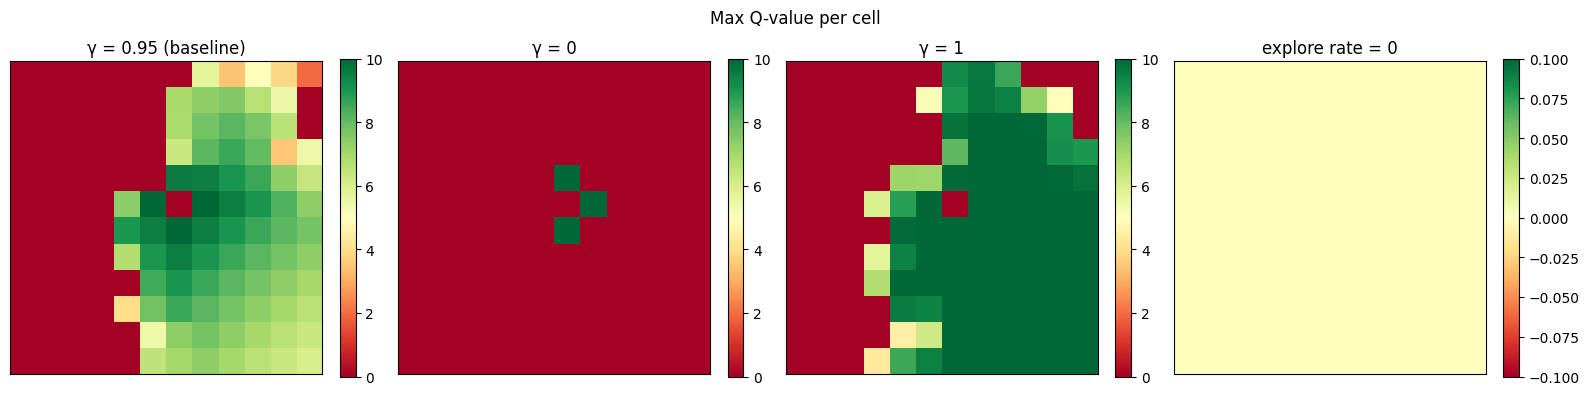

In [21]:
def run_greedy(env, q_table, max_steps):
    """Run one episode with explore rate 0. Returns total reward and number of steps."""
    env.verbose = False
    env.reset()
    state = env.get_state_id()
    total = 0
    for step in range(max_steps):
        _, reward, terminated, _ = env.step(update_action(env, state, 0, q_table))
        state = env.get_state_id()
        total += reward
        if terminated:
            break
    return total, step + 1

experiments = {
    'γ = 0.95 (baseline)': dict(gamma=GAMMA, epsilon=EPSILON, epsilon_min=EPSILON_MIN),
    'γ = 0':               dict(gamma=0.0,   epsilon=EPSILON, epsilon_min=EPSILON_MIN),
    'γ = 1':               dict(gamma=1.0,   epsilon=EPSILON, epsilon_min=EPSILON_MIN),
    'explore rate = 0':    dict(gamma=GAMMA, epsilon=0.0,     epsilon_min=0.0),
}
exp_tables = {}
fig, axes = plt.subplots(1, len(experiments), figsize=(16, 4))
for ax, (name, p) in zip(axes, experiments.items()):
    q, _, _, rpe, _, _ = train_q_learning(env, np.zeros((num_states, num_actions)), NUM_EPISODES,
                                        MAX_STEPS_PER_EPISODE, p['gamma'], p['epsilon_min'],
                                        MIN_LEARNING_RATE, epsilon=p['epsilon'])
    exp_tables[name] = q
    greedy_reward, greedy_steps = run_greedy(env, q, 100)
    print(f"{name:20s} goal reached in {np.sum(rpe == 10):3d}/{NUM_EPISODES} training episodes | "
          f"greedy agent: reward {greedy_reward}, {greedy_steps} steps | non-zero Q-values: {(q != 0).sum()}")
    im = ax.imshow(q.max(axis=1).reshape(env.initial_observation.shape), cmap='RdYlGn')
    ax.set_title(name)
    ax.set_xticks([]); ax.set_yticks([])
    fig.colorbar(im, ax=ax, fraction=0.046)
fig.suptitle('Max Q-value per cell')
fig.tight_layout()
plt.show()

### ❓ What do the heatmaps show?
**Max over actions** shows the estimated state value V(s) = max_a Q(s, a) for every cell. The goal is blank. The cells next to it have value 10, because the next step gives the reward directly. Each step further away multiplies by γ = 0.95 (9.5, 9.0, 8.6, ...), so V(s) ≈ 10·γ^(d−1), where d is the number of steps to the goal. The values form a "hill" around the goal, and the greedy policy simply climbs it.

The **left and upper part is 0** because the agent never went there. The start is in the lower right, so once ε was small it only explored the area between the start and the goal. Q-learning only learns values for states it visits. Cells at the edge of the explored area (e.g. 3.5 in the top right) were visited only a few times and have not converged.

The **per-action heatmaps** show Q(s, a) for one action. For example, "up" (action 0) is highest directly below the goal (10.0) and 0 above it, and "left" is highest to the right of the goal. Comparing the four maps shows which direction is best in each cell, and that is exactly the greedy policy printed by `q_table.argmax(axis=1)` above.

### ❓ What happens with γ = 0 or γ = 1?
**γ = 0:** the target is only the immediate reward, so the agent cares only about the next step. Only the actions that step directly into the goal get a value (10). In the experiment there are only 3 non-zero Q-values in the whole table. All other values stay 0, so there is no gradient that leads towards the goal. The greedy agent gets stuck (argmax picks "up" on ties) and never reaches the goal (reward 0 after 100 steps).

**γ = 1:** there is no discounting. Every path that eventually reaches the goal is worth 10, no matter how long it is, so in theory the agent has **no preference for the shortest path**. The heatmap is almost flat at 10 over the whole explored area. Our greedy agent still found the 9-step path, but only because the values far from the goal had not fully converged yet (cells close to the goal reached 10 first). With fully converged values the greedy policy is determined by ties and can take detours or loop. In tasks with non-zero step rewards and no end, γ = 1 can also make the values unbounded.

### ❓ Every step gives reward 0. How does the agent still learn the shortest path?
Through **discounting**. The +10 at the goal is passed backwards one step at a time through the max Q(s', a') term, and it is multiplied by γ at each step. A goal reached after d steps is worth 10·γ^(d−1), so a shorter path always has a higher value. In the greedy step, the action leading to the neighbour closest to the goal therefore has the highest Q-value. This only works for γ < 1 (see γ = 1 above). Another option would be a negative reward for every step.

### ❓ What happens if the exploration rate is 0 from the start?
All Q-values start at 0, so `argmax` always returns action 0 ("up"). The agent walks to the top edge and keeps pushing against it. Every step gives reward 0, and the target is 0 + γ·0 = 0, so the Q-table never changes and the agent keeps doing the same thing. In the experiment the goal was reached in **0 of 500** episodes and all Q-values are still 0. Even with random tie-breaking, the agent would only exploit the first path it happened to find, with no reason to look for a shorter one. Exploration is needed both to find the reward and to find better paths.

### ❓ Why do we set the exploration rate to 0 when we show the trained agent?
Exploration is only needed **during learning**. To show (and evaluate) what the agent has learned, we want it to follow its learned policy and always pick the best action according to the Q-table. Random actions would make the path longer and different every time we run it, so we could not tell whether the policy itself is good. With ε = 0 the agent takes the optimal 9 steps.

## 🌉 Problem 2: Q-learning in the Trondheim environment
### ❗️ The problem
In the second problem, you will train an agent to navigate from a start position to a goal position using Q-learning, similar to the first problem, but now in a larger and more complex map of Trondheim with water (not allowed), land, bus lanes and bus stops (which teleport the agent to the other bus stop).

### 📋 Formal requirements
1. **Implementation**:
   - Initialize the Q-table
   - Reuse the helper functions for Q-learning from Problem 1
   - Choose and tune the hyperparameters
   - Train the agent using Q-learning
   - Plot the number of steps per episode during training
   - Run one episode with the trained agent and verify that it reaches the goal
2. **Discussion**:
   - Has the training converged?
   - Does the agent use the bus stops? Why or why not?
   - What changes with `dead_allowed=True` or `start_random=True`?

In [22]:
env_config = {
    'env_image_path':'image_TRD.png',
    'dead_allowed':False,
    'start_random':False,
}

if not os.path.exists(env_config['env_image_path']):
  print(f"Error: The image path {env_config['env_image_path']} does not exist.")
else:
  env = TrondheimEnv(conf=env_config)
  print(f"Environment successfully created")

Environment successfully created


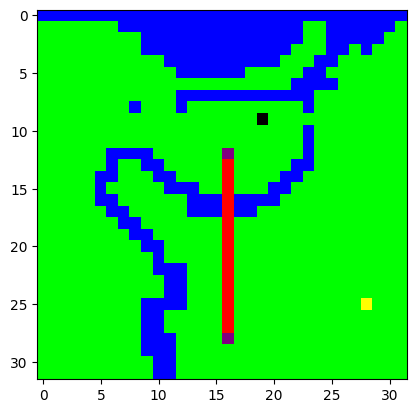

In [23]:
env.reset()
_ = env.render('human')

Next step towards: 
Green Land class area
0


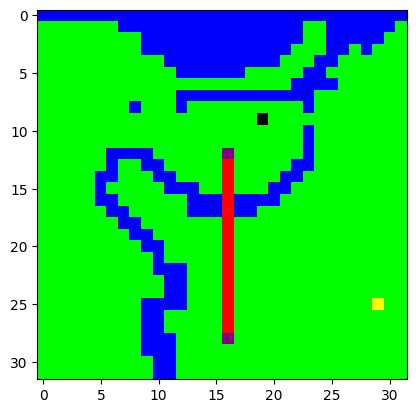

In [24]:
# select the action here
my_action = 'right'

# here is your action
obs, rew, term, info = env.step(action_dict[my_action])
print(rew)
_ = env.render('human')

### Step 1: Initialize Q table

In [25]:
# ====================================
# YOUR CODE GOES HERE
# ====================================
num_states = int(np.prod(env.observation_space.shape))  # 32 * 32 = 1024
num_actions = env.action_space.n
# optimistic initialization: every untried action looks better (1.0) than what the agent has learned so far,
# so the agent systematically tries new actions. With zeros it never discovers the bus (see the experiments below)
Q_INIT = 1.0
q_table = np.full((num_states, num_actions), Q_INIT)
print(f"Q table has this shape: {q_table.shape}")

Q table has this shape: (1024, 4)


### Step 2: Write necessary helper functions for Q-learning

In [26]:
# Task 2: Write necessary helper functions for Q-learning
# ====================================
# YOUR CODE GOES HERE
# ====================================

# YOU DON'T NEED TO DO ANYTHING HERE. The helper functions from Problem 1 can be reused

### Step 3: Play with Hyperparameters

In [27]:
# ====================================
# YOUR CODE GOES HERE
# ====================================
GAMMA = 0.95
NUM_EPISODES = 3000
MIN_EXPLORE_RATE = 0.01
MIN_LEARNING_RATE = 0.1
STEP_SIZE = 1000             # max steps per episode
TRAIN_STEP_SIZE = STEP_SIZE  # STEP_SIZE is overwritten by the demo episode below

### 🐤 Now use Q-learning to learn the Q-table
### Step 4: Train the agent using Q-learning

In [28]:
env.verbose = False # disable printouts while training

# ====================================
# YOUR CODE GOES HERE
# ====================================
q_table, total_reward, steps_per_episode, rewards_per_episode, explore_rate, learning_rate = train_q_learning(
    env, q_table, NUM_EPISODES, TRAIN_STEP_SIZE, GAMMA, MIN_EXPLORE_RATE, MIN_LEARNING_RATE)

print(f"Reached the goal in {np.sum(rewards_per_episode == 10)}/{NUM_EPISODES} episodes")
print(f"Mean steps, first 100 episodes: {steps_per_episode[:100].mean():.1f}, last 100: {steps_per_episode[-100:].mean():.1f}")

Reached the goal in 2975/3000 episodes
Mean steps, first 100 episodes: 558.2, last 100: 21.6


In [29]:
print(f"Total reward after training: {total_reward}, total Explore rate after training: {explore_rate:.4f}")

Total reward after training: 29750, total Explore rate after training: 0.0167


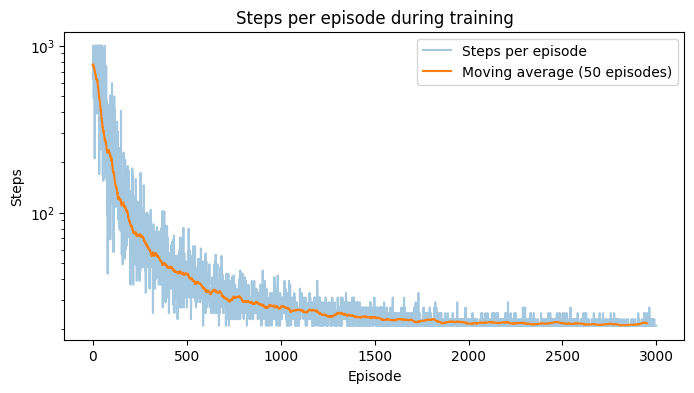

In [30]:
# plot the number of steps the agent needed in each episode
plt.figure(figsize=(8, 4))
plt.plot(steps_per_episode, alpha=0.4, label='Steps per episode')
plt.plot(np.convolve(steps_per_episode, np.ones(50) / 50, mode='valid'), label='Moving average (50 episodes)')
plt.yscale('log')
plt.xlabel('Episode')
plt.ylabel('Steps')
plt.title('Steps per episode during training')
plt.legend()
plt.show()

In [31]:
# Shortest possible path (breadth-first search over the grid, with and without the bus teleport)
from collections import deque

def shortest_path_length(env, start=None, use_bus=True):
    """Returns None if the goal cannot be reached from start"""
    obs = env.initial_observation
    if start is None:
        start = tuple(np.argwhere(obs == env.start_class)[0])
    stops = [tuple(s) for s in np.argwhere(obs == env.busstop_class)]
    dist, queue = {start: 0}, deque([start])
    while queue:
        pos = queue.popleft()
        if obs[pos] == env.final_location_class:
            return dist[pos]
        for d in env.neighbours:
            nxt = (pos[0] + d[0], pos[1] + d[1])
            if not is_valid_idx(obs, nxt) or obs[nxt] in env.not_allowed_area:
                continue
            if obs[nxt] == env.busstop_class:
                if not use_bus:
                    continue
                nxt = stops[1] if nxt == stops[0] else stops[0]
            if nxt not in dist:
                dist[nxt] = dist[pos] + 1
                queue.append(nxt)

env.reset()
print(f"Shortest path with bus: {shortest_path_length(env)} steps, without bus: {shortest_path_length(env, use_bus=False)} steps")
print(f"Steps in the last 20 training episodes: {steps_per_episode[-20:]}")

Shortest path with bus: 21 steps, without bus: 25 steps
Steps in the last 20 training episodes: [21 21 23 21 21 21 21 21 23 21 21 21 21 21 21 21 21 21 21 21]


### ❓ Has the training converged?
**Yes, for the task we trained on (the fixed start).** The number of steps per episode drops from 558 on average in the first 100 episodes (many hit the 1000-step limit) to **21.6** in the last 100. The moving average is flat from about episode 2000. A breadth-first search shows that the shortest possible path is **21 steps** (with the bus; 25 without). The last training episodes take 21 steps, sometimes 23 when one of the ε ≈ 0.017 random actions happens. The greedy agent below also takes exactly 21 steps, so it has found the optimal path.

The **whole Q-table has not converged**, though. Areas the agent rarely visits (e.g. the western part of the map) still have values close to the initial 1.0. The greedy policy reaches the goal from only 59% of the land cells (see the experiment below). Q-learning only converges for states that are visited often enough.

### 🐥 Let's see one episode

In [32]:
env.verbose = False
STEP_SIZE = 100

image_samples = []  # Array to store images

observation = env.reset()
state_id = env.get_state_id()
total_reward = 0

img = env.render()
for _ in range(STEP_SIZE):
    action = update_action(env, state_id, 0, q_table) # explore rate 0: always pick the best action
    observation, reward, terminated, info = env.step(action)
    state_id = env.get_state_id()
    total_reward += reward
    img = env.render()
    image_samples.append(img)
    if terminated:
        break

print(f"Total_reward: ", total_reward)

Total_reward:  10


In [33]:
print(f"The greedy agent needed {len(image_samples)} steps")

The greedy agent needed 21 steps


### Simple animation of agent movement in one episode

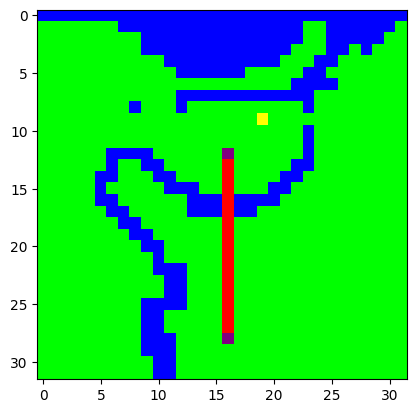

In [34]:
# let's make an animation of this, because it's fun
# nothing for you to do here - just run the code

import os
import matplotlib.animation as animation

height = img.shape[0]
width = img.shape[1]

output_folder = 'output'
if not os.path.exists(output_folder):
    os.makedirs(output_folder)

fig = plt.figure()
imgs = []
for i in range(len(image_samples)):
    im = plt.imshow(image_samples[i].reshape(height, width, 3), animated=True)
    imgs.append([im])

animate = animation.ArtistAnimation(fig, imgs, interval=80, blit=True, repeat_delay=1000)
filename_gif = os.path.join(output_folder, 'animation_trd.gif')
animate.save(filename_gif)
plt.show()

### ❓ Does the agent use the bus stops? Why or why not?
**Yes.** The greedy agent walks left and down to the lower bus stop (28, 16), is teleported to the upper stop (12, 16), and walks the last 6 steps up and right to the goal: **21 steps instead of 25** without the bus. With γ = 0.95, the bus path is worth 10·0.95²⁰ ≈ 3.58 at the start, compared with 10·0.95²⁴ ≈ 2.92 for the direct path. The agent therefore prefers it because it is shorter. The red bus lane itself has no special effect; it behaves like normal land.

The bus is, however, **hard to discover**. With a zero-initialized Q-table (the "Q init 0" row below) the agent learns the direct 25-step path and never uses the bus. This happened for all 6 seeds we tried. The bus stop lies off the direct route (it means moving away from the goal), and its value only becomes visible after the agent has stepped on it and has also learned the values around the upper stop. Once ε has decayed, the agent just exploits the route it already knows. We therefore initialize the Q-table **optimistically (1.0)**. Every untried action then looks better than the ones the agent has learned are useless, so the agent tries all of them systematically and finds the bus.

821 of 821 land cells are connected to the goal



baseline (Q init 1)      training: goal 2975/3000, died    0 | mean steps last 100 ep.   21.6 | greedy from fixed start:  21 steps | greedy reaches goal from  59% of the land cells


Q init 0                 training: goal 2967/3000, died    0 | mean steps last 100 ep.   25.4 | greedy from fixed start:  25 steps | greedy reaches goal from  57% of the land cells


dead_allowed, Q init 1   training: goal 2771/3000, died  229 | mean steps last 100 ep.   21.3 | greedy from fixed start:  21 steps | greedy reaches goal from  32% of the land cells


dead_allowed, Q init 0   training: goal    0/3000, died 2999 | mean steps last 100 ep.  195.2 | greedy from fixed start: 200 steps | greedy reaches goal from   1% of the land cells


start_random, Q init 1   training: goal 2969/3000, died    0 | mean steps last 100 ep.   19.2 | greedy from fixed start:  21 steps | greedy reaches goal from 100% of the land cells


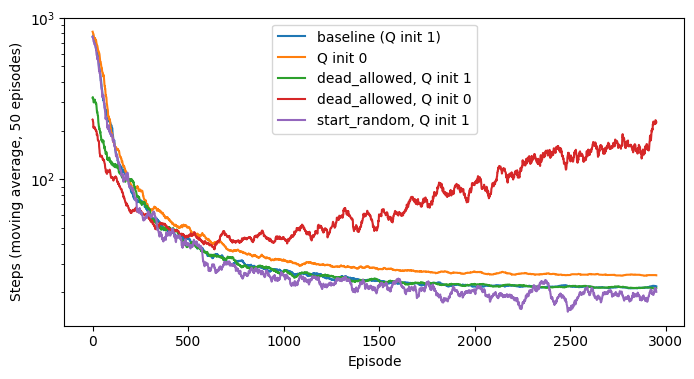

In [35]:
# Train the same agent with zero Q init, dead_allowed=True and/or start_random=True
def run_greedy_from(env, q_table, cell, max_steps=200):
    """Greedy episode that starts in the given cell. Returns (reached goal, steps)."""
    env.verbose = False
    env.reset()
    start = tuple(np.argwhere(env.observation == env.start_class)[0])
    for grid in (env.observation, env.initial_observation):
        grid[start] = env.normal_land_class
        grid[cell] = env.start_class
    state = env.get_state_id()
    for step in range(max_steps):
        _, reward, terminated, _ = env.step(update_action(env, state, 0, q_table))
        state = env.get_state_id()
        if terminated:
            return reward == 10, step + 1
    return False, max_steps

env.reset()
fixed_start = tuple(np.argwhere(env.initial_observation == env.start_class)[0])
land_cells = [tuple(c) for c in np.argwhere(np.isin(env.initial_observation, [env.start_class, env.normal_land_class, 3]))]
reachable = [c for c in land_cells if shortest_path_length(env, start=c) is not None]
print(f"{len(reachable)} of {len(land_cells)} land cells are connected to the goal\n")

def evaluate(env_v, q):
    """Greedy agent from the fixed start, and from every land cell connected to the goal"""
    _, steps_fixed = run_greedy_from(env_v, q, fixed_start)
    reached = [run_greedy_from(env_v, q, c)[0] for c in reachable]
    return steps_fixed, np.mean(reached)

def train_variant(dead_allowed, start_random, q_init):
    env_v = TrondheimEnv(conf={'env_image_path': 'image_TRD.png',
                               'dead_allowed': dead_allowed, 'start_random': start_random})
    q = np.full((num_states, num_actions), q_init)
    q, _, spe, rpe, _, _ = train_q_learning(env_v, q, NUM_EPISODES, TRAIN_STEP_SIZE, GAMMA,
                                            MIN_EXPLORE_RATE, MIN_LEARNING_RATE)
    return env_v, q, spe, rpe

configs = {   # name: (dead_allowed, start_random, Q init)
    'baseline (Q init 1)':            (False, False, Q_INIT),
    'Q init 0':                       (False, False, 0.0),
    'dead_allowed, Q init 1':         (True,  False, Q_INIT),
    'dead_allowed, Q init 0':         (True,  False, 0.0),
    'start_random, Q init 1':         (False, True,  Q_INIT),
}
variants = {}
for name, (dead, rand, q_init) in configs.items():
    if name.startswith('baseline'):
        env_v, q, spe, rpe = env, q_table, steps_per_episode, rewards_per_episode  # already trained above
    else:
        env_v, q, spe, rpe = train_variant(dead, rand, q_init)
    goals, deaths = np.sum(rpe == 10), np.sum(rpe == -1)
    steps_fixed, success = evaluate(env_v, q)
    variants[name] = spe
    print(f"{name:24s} training: goal {goals:4d}/{NUM_EPISODES}, died {deaths:4d} | "
          f"mean steps last 100 ep. {spe[-100:].mean():6.1f} | greedy from fixed start: {steps_fixed:3d} steps | "
          f"greedy reaches goal from {success:4.0%} of the land cells")

fig, ax = plt.subplots(figsize=(8, 4))
for name, spe in variants.items():
    ax.plot(np.convolve(spe, np.ones(50) / 50, mode='valid'), label=name)
ax.set_yscale('log')
ax.set_xlabel('Episode')
ax.set_ylabel('Steps (moving average, 50 episodes)')
ax.legend()
plt.show()

### ❓ What changes with `dead_allowed=True` or `start_random=True`?
**`dead_allowed=True`:** stepping into the water ends the episode with reward −1, instead of just blocking the move. The agent has to learn to avoid the water (Q(s, into water) → −1), and early episodes end quickly. Exploration becomes much harder. With a zero-initialized Q-table the agent **never** reached the goal in 3000 episodes (it died 2999 times): a random walk from the start almost always hits the water before it finds the goal. The only signal is "water is bad", so the agent learns to avoid the water but has nothing to move towards. As ε decays it wanders longer and longer before dying (the rising red curve). With the optimistic initialization it works: goal reached in 2771/3000 episodes, deaths mostly early, and the same optimal 21-step bus path.

**`start_random=True`:** every episode starts at a random land cell, so the agent has to learn values for the **whole map**, not just one path. Episode lengths vary more because the starts are at different distances from the goal. The result is a general policy: the greedy agent reaches the goal from **100% of the 821 land cells**, compared with 59% for the agent trained with a fixed start (which only knows the area around its own route). From the original start it still takes the optimal 21 steps. Random starts work as a kind of extra exploration, and they need more episodes to converge everywhere.

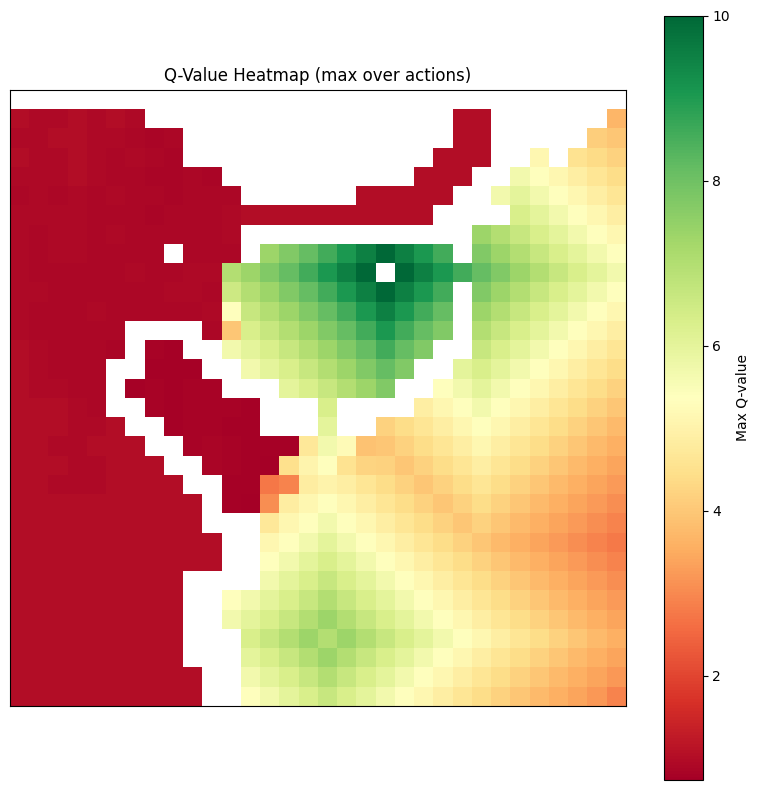

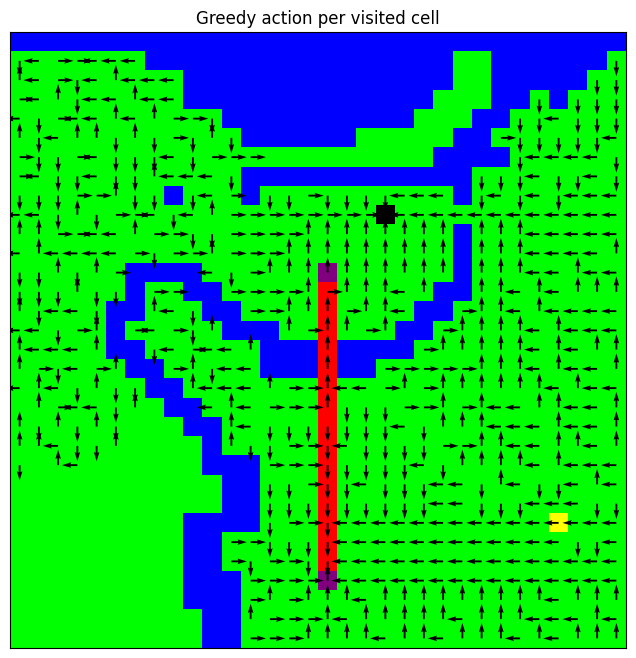

In [36]:
# ====================================
# YOUR CODE GOES HERE: plot the q values!
# ====================================
env.reset()
show_q_heatmap(env, q_table)

# greedy policy as arrows on top of the map (only for states the agent has visited)
nrows, ncols = env.initial_observation.shape
best = q_table.argmax(axis=1).reshape(nrows, ncols)
visited = (q_table != Q_INIT).any(axis=1).reshape(nrows, ncols)
dx = np.array([0, -1, 0, 1])[best]   # up, left, down, right
dy = np.array([1, 0, -1, 0])[best]   # quiver y-axis points up
rows, cols = np.nonzero(visited)

fig, ax = plt.subplots(figsize=(8, 8))
ax.imshow(make_3d(env.initial_observation, env.pallete))
ax.quiver(cols, rows, dx[rows, cols], dy[rows, cols], scale=40, width=0.003)
ax.set_xticks([]); ax.set_yticks([])
ax.set_title('Greedy action per visited cell')
plt.show()

The values increase towards the goal, as in Problem 1. The bus shows up in the heatmap: the cells around the **lower** bus stop have high values (≈ 7), because one step onto the stop teleports the agent to the upper stop, 6 steps from the goal (10·0.95⁶ ≈ 7.4). Cells at the same distance on the right side, without the bus, have values of only 3–4. The western part of the map, which the agent rarely visited, keeps values close to the optimistic initial value of 1.0, and the arrows there are mostly arbitrary.